# Optimal Transport Experiments: HCGM, CGAL, AdaPD, and AccPD

This notebook is self-contained: it does not use the benchmark runner, CVXPY, SCS, OTDD, or the reference modules. It loads the 2,000 x 2,000 CIFAR-10/MNIST ResNet-18 cost matrix, solves a SciPy/HiGHS LP for ground truth, runs HCGM, CGAL, AdaPD, and AccPD parameter sweeps, and plots primal residual and feasibility gap.

## Configuration

The default is a 2,000 x 2,000 CIFAR-10/MNIST ResNet-18 instance generated by the OTDD/Torchvision pipeline. Run `generate_ot_cost.py` from this directory before executing the notebook. The HiGHS LP has 4,000,000 variables and can require substantial memory and time.

In [1]:
from __future__ import annotations

import csv
from dataclasses import dataclass
import hashlib
from pathlib import Path
import re
import time

import numpy as np
from scipy import sparse
from scipy.optimize import linprog
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## Problem Loading

In [2]:
# Launch from this directory so the relative dataset path resolves correctly.
COST_FILE = Path("datasets/OTDD/cifar10_mnist_2000x2000_resnet18.npy")
NORMALIZE_COST = True

# Progress output is sparse by default: iterations 10, 20, 40, 80, ... and the final one.
VERBOSE_RUNS = True

# Powers of ten used for the separate tuning sweeps.
HCGM_LAMBDAS = [1e1, 1e2, 1e3, 1e4]
CGAL_LAMBDAS = [1e0, 1e1, 1e2, 1e3]
ADAPD_ALPHAS = [1e0, 1e1, 1e2, 1e3]
ACCPD_ALPHAS = [1e0, 1e1, 1e2, 1e3]

# Chosen based on the individual tuning plots.
SELECTED_RUNS = [
    ("HCGM", 1e3),
    ("CGAL-cst", 1e1),
    ("CGAL-dcr", 1e2),
    ("AdaPD", 1e1),
    ("AccPD", 1e1),
]

# Set this to 10 while debugging; restore to 10_000 for actual tuning.
RUN_TUNING_EXPERIMENT = True
TUNING_MAXITER = 1000
RUN_LONG_EXPERIMENT = True
LONG_MAXITER = 10_000


In [3]:
@dataclass(frozen=True)
class OTProblem:
    C: np.ndarray
    s: np.ndarray
    d: np.ndarray
    name: str = "OT"


def normalize_cost(C: np.ndarray) -> np.ndarray:
    C = np.asarray(C, dtype=np.float64)
    C = C - np.min(C)
    positive = C[C > 0]
    scale = np.median(positive) if positive.size else np.max(np.abs(C))
    if scale > 0:
        C = C / scale
    return C

DATA_PATH: Path | None = None


def load_problem() -> OTProblem:
    global DATA_PATH
    if COST_FILE is None:
        raise ValueError("COST_FILE must point to a real .npy cost matrix")
    path = Path(COST_FILE)
    if not path.exists():
        raise FileNotFoundError(f"Cost matrix not found: {path} (cwd={Path.cwd()})")
    DATA_PATH = path
    C = np.asarray(np.load(path), dtype=np.float64)
    n, m = C.shape
    if NORMALIZE_COST:
        C = normalize_cost(C)
    s = np.full(n, 1.0 / n, dtype=np.float64)
    d = np.full(m, 1.0 / m, dtype=np.float64)
    return OTProblem(C=C, s=s, d=d, name=path.stem)


problem = load_problem()
C, s, d = problem.C, problem.s, problem.d

print(problem.name)
print(f"C shape: {C.shape}; variables: {C.size:,}")
print(f"sum(s)={s.sum():.12f}, sum(d)={d.sum():.12f}")
print(f"cost range: [{C.min():.3g}, {C.max():.3g}]")

cifar10_mnist_2000x2000_resnet18
C shape: (2000, 2000); variables: 4,000,000
sum(s)=1.000000000000, sum(d)=1.000000000000
cost range: [0, 4.31]


## SciPy LP Ground Truth
The notebook first looks beside the cost matrix for `<cost-stem>_ground_truth.npz`. If the cache is present and matches the current normalized cost, marginals, and fixed HiGHS tolerances, it is loaded; otherwise HiGHS solves the LP once and writes a compact cache there.

In [4]:
def solve_ot_ground_truth_linprog(C: np.ndarray, s: np.ndarray, d: np.ndarray):
    n, m = C.shape
    A_row = sparse.kron(
        sparse.eye(n, format="csr"),
        sparse.csr_matrix(np.ones((1, m))),
        format="csr",
    )
    A_col = sparse.kron(
        sparse.csr_matrix(np.ones((1, n))),
        sparse.eye(m, format="csr"),
        format="csr",
    )
    A_eq = sparse.vstack([A_row, A_col], format="csr")
    b_eq = np.concatenate([s, d])

    tic = time.perf_counter()
    result = linprog(
        C.reshape(-1),
        A_eq=A_eq,
        b_eq=b_eq,
        bounds=(0.0, None),
        method="highs",
        options={
            "disp": True,
            "primal_feasibility_tolerance": 1e-10,
            "dual_feasibility_tolerance": 1e-10,
        },
    )
    elapsed = time.perf_counter() - tic

    if not result.success:
        raise RuntimeError(result.message)

    X_star = result.x.reshape(n, m)
    return float(result.fun), X_star, result, elapsed


def ground_truth_cache_path(data_path: Path | None) -> Path | None:
    if data_path is None:
        return None
    return data_path.with_name(f"{data_path.stem}_ground_truth.npz")


def ground_truth_fingerprint(C: np.ndarray, s: np.ndarray, d: np.ndarray) -> str:
    digest = hashlib.sha256()
    for values in (C, s, d):
        array = np.ascontiguousarray(values, dtype=np.float64)
        digest.update(np.asarray(array.shape, dtype=np.int64).tobytes())
        digest.update(array.tobytes())
    digest.update(b"highs-ds")
    digest.update(repr((1e-10, 1e-10)).encode())
    return digest.hexdigest()


def load_ground_truth_cache(cache_file: Path | None, C: np.ndarray, s: np.ndarray, d: np.ndarray):
    if cache_file is None or not cache_file.exists():
        return None
    try:
        with np.load(cache_file, allow_pickle=False) as data:
            if str(data["fingerprint"].item()) != ground_truth_fingerprint(C, s, d):
                print(f"Ignoring stale ground-truth cache: {cache_file}")
                return None
            f_star = float(data["f_star"].item())
            X_shape = tuple(np.asarray(data["X_shape"], dtype=int).tolist())
            X_star = sparse.coo_matrix(
                (data["X_data"], (data["X_rows"], data["X_cols"])),
                shape=X_shape,
            ).toarray()
    except (KeyError, OSError, ValueError) as exc:
        print(f"Ignoring invalid ground-truth cache {cache_file}: {exc}")
        return None
    if X_star.shape != C.shape:
        print(f"Ignoring shape-incompatible ground-truth cache: {cache_file}")
        return None
    return f_star, X_star


def save_ground_truth_cache(cache_file: Path | None, f_star: float, X_star: np.ndarray, C: np.ndarray, s: np.ndarray, d: np.ndarray) -> None:
    if cache_file is None:
        return
    cache_file.parent.mkdir(parents=True, exist_ok=True)
    X_coo = sparse.coo_matrix(X_star)
    np.savez_compressed(
        cache_file,
        f_star=np.asarray(f_star),
        X_shape=np.asarray(X_star.shape, dtype=np.int64),
        X_rows=X_coo.row,
        X_cols=X_coo.col,
        X_data=X_coo.data,
        s=np.asarray(s, dtype=np.float64),
        d=np.asarray(d, dtype=np.float64),
        fingerprint=np.asarray(ground_truth_fingerprint(C, s, d)),
    )


cache_file = ground_truth_cache_path(DATA_PATH)
cached_ground_truth = load_ground_truth_cache(cache_file, C, s, d)
if cached_ground_truth is not None:
    f_star, X_star = cached_ground_truth
    lp_time = 0.0
    ground_truth_source = f"cache: {cache_file}"
else:
    f_star, X_star, _, lp_time = solve_ot_ground_truth_linprog(C, s, d)
    save_ground_truth_cache(cache_file, f_star, X_star, C, s, d)
    ground_truth_source = f"new LP solve; saved to {cache_file}" if cache_file is not None else "new LP solve"

row_res = np.linalg.norm(X_star.sum(axis=1) - s) / np.linalg.norm(s)
col_res = np.linalg.norm(X_star.sum(axis=0) - d) / np.linalg.norm(d)
neg_res = np.linalg.norm(np.minimum(X_star, 0.0))

print(f"ground truth source = {ground_truth_source}")
print(f"f_star = {f_star:.12e}")
print(f"LP solve time = {lp_time:.2f} s")
print(f"LP feasibility: rows={row_res:.2e}, cols={col_res:.2e}, neg={neg_res:.2e}")

Running HiGHS 1.8.0 (git hash: 222cce7): Copyright (c) 2024 HiGHS under MIT licence terms
Coefficient ranges:
  Matrix [1e+00, 1e+00]
  Cost   [2e-02, 4e+00]
  Bound  [0e+00, 0e+00]
  RHS    [5e-04, 5e-04]


Presolving model


4000 rows, 4000000 cols, 8000000 nonzeros  0s


3999 rows, 4000000 cols, 7998000 nonzeros  21s


Presolve : Reductions: rows 3999(-1); columns 4000000(-0); elements 7998000(-2000)
Solving the presolved LP


...

      47524     8.1879191704e-01 Pr: 60(0.063) 154s


      47823     8.1899602123e-01 Pr: 0(0) 160s
      47824     8.1899465847e-01 Pr: 0(0) 160s


      47824     8.1899465847e-01 Pr: 0(0) 160s
Solving the original LP from the solution after postsolve


Model status        : Optimal
Simplex   iterations: 47824
Objective value     :  8.1899465847e-01
Relative P-D gap    :  2.7755575616e-15
HiGHS run time      :        160.70


ground truth source = new LP solve; saved to datasets/OTDD/cifar10_mnist_2000x2000_resnet18_ground_truth.npz
f_star = 8.189946584651e-01
LP solve time = 169.79 s
LP feasibility: rows=0.00e+00, cols=0.00e+00, neg=0.00e+00


## OT Oracle and Diagnostics

In [5]:
def ot_lmo_rows(C: np.ndarray, row_potential: np.ndarray) -> np.ndarray:
    if hasattr(C, "lmo_rows"):
        return C.lmo_rows(row_potential)
    n, m = C.shape
    row_potential = np.asarray(row_potential, dtype=np.float64).reshape(n)
    return np.argmin(C + row_potential[:, None], axis=0)


def ot_lmo(C: np.ndarray, d: np.ndarray, row_potential: np.ndarray) -> np.ndarray:
    # Reference version retained for small correctness tests.
    d = np.asarray(d, dtype=np.float64).reshape(-1)
    rows = ot_lmo_rows(C, row_potential)
    S = np.zeros_like(C, dtype=np.float64)
    S[rows, np.arange(C.shape[1])] = d
    return S


def update_assignment_average(X: np.ndarray, rows: np.ndarray, d: np.ndarray, weight: float, total_weight: float) -> None:
    # Each LMO has one nonzero per column; avoid allocating a dense S matrix.
    X *= total_weight / (total_weight + weight)
    X[rows, np.arange(X.shape[1])] += weight / (total_weight + weight) * d


def ot_metrics(C: np.ndarray, s: np.ndarray, d: np.ndarray, X: np.ndarray) -> dict[str, float]:
    primal_obj = float(np.sum(C * X))
    row_feas = float(np.linalg.norm(X.sum(axis=1) - s) / np.linalg.norm(s))
    col_feas = float(np.linalg.norm(X.sum(axis=0) - d) / np.linalg.norm(d))
    neg_feas = float(np.linalg.norm(np.minimum(X, 0.0)))
    feasibility_gap = float(np.sqrt(row_feas**2 + col_feas**2 + neg_feas**2))

    return {
        "primal_obj": primal_obj,
        "row_feas": row_feas,
        "col_feas": col_feas,
        "neg_feas": neg_feas,
        "feasibility_gap": feasibility_gap,
    }


def make_log_schedule(maxiter: int) -> set[int]:
    early = np.arange(1, min(maxiter, 100) + 1)
    geom = np.unique(np.ceil(1.08 ** np.arange(300)).astype(int))
    geom = geom[(geom >= 1) & (geom <= maxiter)]
    return set(np.concatenate([early, geom, np.array([maxiter])]).astype(int))

def make_progress_schedule(maxiter: int) -> set[int]:
    schedule = {maxiter}
    k = 10
    while k <= maxiter:
        schedule.add(k)
        k *= 2
    return schedule


def new_history(name: str, lambda0: float, method: str, bound: str | None = None) -> dict:
    return {
        "name": name,
        "method": method,
        "lambda0": lambda0,
        "bound": bound,
        "iter": [],
        "time": [],
        "primal_obj": [],
        "row_feas": [],
        "col_feas": [],
        "neg_feas": [],
        "feasibility_gap": [],
    }


def append_metrics(history: dict, k: int, elapsed: float, C: np.ndarray, s: np.ndarray, d: np.ndarray, X: np.ndarray):
    metrics = ot_metrics(C, s, d, X)
    history["iter"].append(k)
    history["time"].append(elapsed)
    for key, value in metrics.items():
        history[key].append(value)

def report_progress(history: dict, k: int, progress_schedule: set[int], C: np.ndarray, s: np.ndarray, d: np.ndarray, X: np.ndarray) -> None:
    if not VERBOSE_RUNS or k not in progress_schedule:
        return
    if history["iter"] and history["iter"][-1] == k:
        objective = history["primal_obj"][-1]
        feasibility = history["feasibility_gap"][-1]
    else:
        metrics = ot_metrics(C, s, d, X)
        objective = metrics["primal_obj"]
        feasibility = metrics["feasibility_gap"]
    print(f"{history['name']}: iter={k:,} objective={objective:.6e} feasibility={feasibility:.3e}")

## HCGM, CGAL, AdaPD, and AccPD

In [6]:
def hcgm_ot(problem: OTProblem, lambda0: float, maxiter: int) -> dict:
    C, s, d = problem.C, problem.s, problem.d
    n, m = C.shape
    cost = C
    X = np.zeros((n, m), dtype=np.float64)
    log_schedule = make_log_schedule(maxiter)
    progress_schedule = make_progress_schedule(maxiter)
    history = new_history(f"HCGM λ0={lambda0:g}", lambda0=lambda0, method="HCGM")
    tic = time.perf_counter()

    for k in range(1, maxiter + 1):
        eta = 2.0 / (k + 1.0)
        lam = lambda0 * np.sqrt(k + 1.0)
        row_res = X.sum(axis=1) - s
        rows = ot_lmo_rows(cost, lam * row_res)
        X *= 1.0 - eta
        X[rows, np.arange(m)] += eta * d

        if k in log_schedule:
            append_metrics(history, k, time.perf_counter() - tic, C, s, d, X)
        report_progress(history, k, progress_schedule, C, s, d, X)

    history["X"] = X
    return history


def cgal_ot(problem: OTProblem, lambda0: float, bound: str, maxiter: int) -> dict:
    C, s, d = problem.C, problem.s, problem.d
    n, m = C.shape
    cost = C
    X = np.zeros((n, m), dtype=np.float64)
    y = np.zeros(n, dtype=np.float64)
    normA = np.sqrt(m)
    DX = np.sqrt(2.0) * np.linalg.norm(d)
    log_schedule = make_log_schedule(maxiter)
    progress_schedule = make_progress_schedule(maxiter)
    history = new_history(f"CGAL-{bound} λ0={lambda0:g}", lambda0=lambda0, method="CGAL", bound=bound)
    tic = time.perf_counter()

    for k in range(1, maxiter + 1):
        eta = 2.0 / (k + 1.0)
        lam = lambda0 * np.sqrt(k + 1.0)
        row_res = X.sum(axis=1) - s
        rows = ot_lmo_rows(cost, y + lam * row_res)
        X *= 1.0 - eta
        X[rows, np.arange(m)] += eta * d
        row_res = X.sum(axis=1) - s

        if bound == "cst":
            denom = np.linalg.norm(row_res) ** 2
            sigma = 0.0 if denom == 0.0 else eta**2 * lam * normA**2 * DX**2 / (2.0 * denom)
            sigma = min(lambda0, max(0.0, sigma))
        elif bound == "dcr":
            sigma = lambda0 / (2.0 * np.sqrt(k + 1.0))
        else:
            raise ValueError("bound must be 'cst' or 'dcr'")

        y = y + sigma * row_res

        if k in log_schedule:
            append_metrics(history, k, time.perf_counter() - tic, C, s, d, X)
        report_progress(history, k, progress_schedule, C, s, d, X)

    history["X"] = X
    history["y"] = y
    return history


def adapd_ot(problem: OTProblem, alpha: float, maxiter: int) -> dict:
    C, s, d = problem.C, problem.s, problem.d
    n, _ = C.shape
    cost = C
    lam = np.zeros(n, dtype=np.float64)
    X_sum = np.zeros_like(C)
    lam_sum = np.zeros(n, dtype=np.float64)
    eta_sum = 0.0
    S_t = 1e-8
    log_schedule = make_log_schedule(maxiter)
    progress_schedule = make_progress_schedule(maxiter)
    history = new_history(f"AdaPD α={alpha:g}", lambda0=alpha, method="AdaPD")
    tic = time.perf_counter()

    for k in range(1, maxiter + 1):
        rows = ot_lmo_rows(cost, lam)
        grad = s.copy()
        np.add.at(grad, rows, -d)
        S_t += np.dot(grad, grad)
        eta = alpha / np.sqrt(S_t)
        lam = lam - eta * grad
        update_assignment_average(X_sum, rows, d, eta, eta_sum)
        eta_sum += eta
        lam_sum += eta * lam

        if k in log_schedule:
            append_metrics(history, k, time.perf_counter() - tic, C, s, d, X_sum)
        report_progress(history, k, progress_schedule, C, s, d, X_sum)

    history["X"] = X_sum
    history["y"] = lam_sum / eta_sum
    return history


def accpd_ot(problem: OTProblem, alpha: float, maxiter: int) -> dict:
    C, s, d = problem.C, problem.s, problem.d
    n, _ = C.shape
    cost = C
    lam_hat = np.zeros(n, dtype=np.float64)
    lam_tilde = lam_hat.copy()
    X_sum = np.zeros_like(C)
    lam_sum = np.zeros(n, dtype=np.float64)
    alpha_k = 0.0
    alpha_sum = 0.0
    S_t = 1e-8
    log_schedule = make_log_schedule(maxiter)
    progress_schedule = make_progress_schedule(maxiter)
    history = new_history(f"AccPD α={alpha:g}", lambda0=alpha, method="AccPD")
    tic = time.perf_counter()

    for k in range(1, maxiter + 1):
        alpha_k = (1.0 + np.sqrt(1.0 + 4.0 * alpha_k**2)) / 2.0
        tau = 1.0 / alpha_k
        lam = tau * lam_tilde + (1.0 - tau) * lam_hat
        rows = ot_lmo_rows(cost, lam)
        grad = s.copy()
        np.add.at(grad, rows, -d)
        S_t += alpha_k**2 * np.dot(grad, grad)
        eta = alpha / np.sqrt(S_t)
        lam_tilde = lam_tilde - alpha_k * eta * grad
        lam_hat = lam - eta * grad
        update_assignment_average(X_sum, rows, d, alpha_k, alpha_sum)
        alpha_sum += alpha_k
        lam_sum += alpha_k * lam_hat

        if k in log_schedule:
            append_metrics(history, k, time.perf_counter() - tic, C, s, d, X_sum)
        report_progress(history, k, progress_schedule, C, s, d, X_sum)

    history["X"] = X_sum
    history["y"] = lam_sum / alpha_sum
    return history

In [7]:
# Small correctness check for the dense-cost LMO used by every method.
rng = np.random.default_rng(123)
C_test = rng.random((9, 7))
y_test = rng.normal(size=C_test.shape[0])
rows_expected = np.argmin(C_test + y_test[:, None], axis=0)
assert np.array_equal(ot_lmo_rows(C_test, y_test), rows_expected)
print("Dense-cost LMO correctness check passed.")

def objective_residual(history: dict, f_star: float) -> np.ndarray:
    scale = max(1.0, abs(f_star))
    primal = np.asarray(history["primal_obj"], dtype=float)
    primal_residual = np.abs(primal - f_star) / scale
    return np.maximum(primal_residual, 1e-16)

def plot_ot_histories(histories: dict[str, dict], f_star: float, title: str | None = None):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
    panels = [
        ("primal_residual", "Primal objective residual"),
        ("feasibility_gap", "Feasibility gap"),
    ]
    for ax, (metric, panel_title) in zip(axes, panels):
        for name, hist in histories.items():
            x = np.asarray(hist["iter"], dtype=float)
            if metric == "primal_residual":
                y = objective_residual(hist, f_star)
            else:
                y = np.asarray(hist[metric], dtype=float)
            y = np.maximum(y, 1e-16)
            linestyle = "-"
            ax.loglog(x, y, linestyle=linestyle, linewidth=1.8, label=name)
        ax.set_title(panel_title)
        ax.set_xlabel("LMO calls / iterations")
        ax.set_ylabel("relative residual")
    if title is not None:
        fig.suptitle(title)
    axes[-1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
    return fig, axes

def _csv_run_name(history: dict) -> str:
    method = str(history.get("method", "run")).lower()
    bound = history.get("bound")
    parameter = float(history.get("lambda0", 0.0))
    parameter_text = f"{parameter:g}".replace(".", "p")
    pieces = [method]
    if bound:
        pieces.append(str(bound).lower())
    pieces.append(f"param_{parameter_text}")
    return "_".join(re.sub(r"[^a-z0-9_]+", "_", piece) for piece in pieces)

def export_history_csv(history: dict, f_star: float, output_dir: Path, prefix: str) -> Path:
    output_dir.mkdir(parents=True, exist_ok=True)
    primal_residual = objective_residual(history, f_star)
    path = output_dir / f"{prefix}_{_csv_run_name(history)}.csv"
    fieldnames = [
        "iteration", "time", "primal_obj",
        "primal_residual", "row_feas",
        "col_feas", "neg_feas", "feasibility_gap",
        "method", "parameter", "bound", "name",
    ]
    with path.open("w", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=fieldnames)
        writer.writeheader()
        for i, iteration in enumerate(history["iter"]):
            writer.writerow({
                "iteration": int(iteration),
                "time": float(history["time"][i]),
                "primal_obj": float(history["primal_obj"][i]),
                "primal_residual": float(primal_residual[i]),
                "row_feas": float(history["row_feas"][i]),
                "col_feas": float(history["col_feas"][i]),
                "neg_feas": float(history["neg_feas"][i]),
                "feasibility_gap": float(history["feasibility_gap"][i]),
                "method": history.get("method", ""),
                "parameter": float(history.get("lambda0", 0.0)),
                "bound": history.get("bound") or "",
                "name": history.get("name", ""),
            })
    return path

def export_histories_csv(histories: dict[str, dict], f_star: float, prefix: str) -> list[Path]:
    output_dir = Path("results") / "ot"
    paths = [export_history_csv(history, f_star, output_dir, prefix) for history in histories.values()]
    if not paths:
        return paths
    combined = output_dir / f"{prefix}_all.csv"
    with paths[0].open(newline="") as source:
        fieldnames = csv.DictReader(source).fieldnames
    with combined.open("w", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=["run_file"] + fieldnames)
        writer.writeheader()
        for path in paths:
            with path.open(newline="") as source:
                for row in csv.DictReader(source):
                    writer.writerow({"run_file": path.name, **row})
    print(f"exported {len(paths)} CSV files to {output_dir}/")
    return paths

Dense-cost LMO correctness check passed.


## HCGM tuning

HCGM λ0=10: iter=10 objective=4.072814e-01 feasibility=3.042e+00


HCGM λ0=10: iter=20 objective=4.227475e-01 feasibility=2.522e+00


HCGM λ0=10: iter=40 objective=4.401027e-01 feasibility=2.191e+00


HCGM λ0=10: iter=80 objective=4.611499e-01 feasibility=1.900e+00


HCGM λ0=10: iter=160 objective=4.855476e-01 feasibility=1.632e+00


...

HCGM λ0=10000: iter=80 objective=8.302740e-01 feasibility=2.149e+00


HCGM λ0=10000: iter=160 objective=8.667232e-01 feasibility=1.632e+00


HCGM λ0=10000: iter=320 objective=8.799230e-01 feasibility=1.173e+00


HCGM λ0=10000: iter=640 objective=9.042632e-01 feasibility=7.635e-01


HCGM λ0=10000: iter=1,000 objective=9.089625e-01 feasibility=5.505e-01
finished HCGM λ0=10000: objective=9.089625e-01, feas=5.505e-01


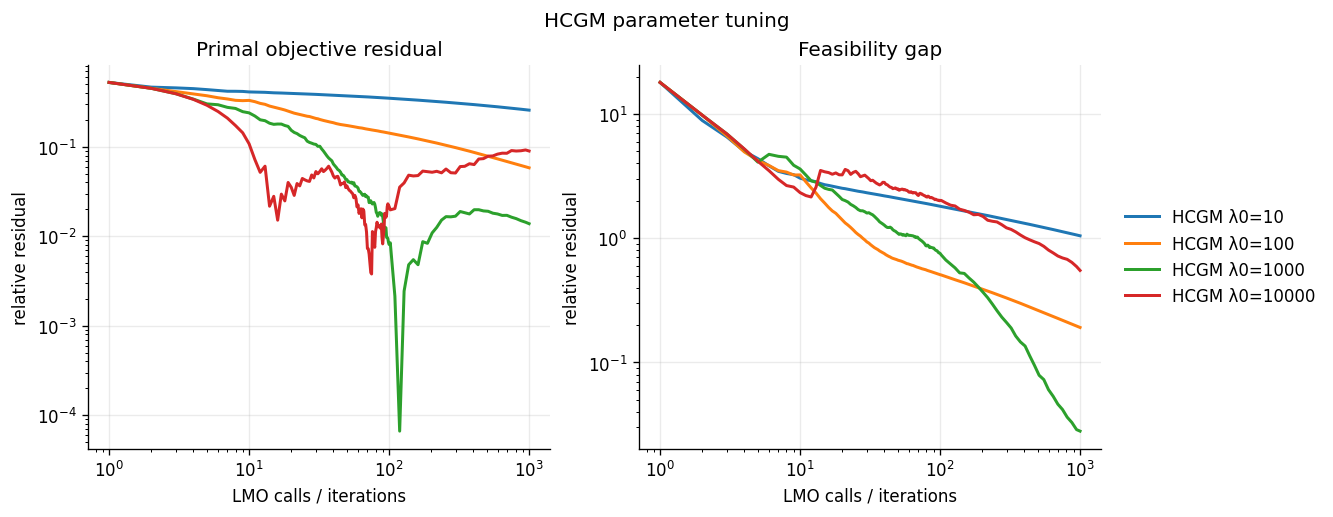

exported 4 CSV files to results/ot/


In [8]:
tuning_histories: dict[str, dict] = {}
hcgm_tuning: dict[str, dict] = {}

if RUN_TUNING_EXPERIMENT:

    for lambda0 in HCGM_LAMBDAS:
        hist = hcgm_ot(problem, lambda0=lambda0, maxiter=TUNING_MAXITER)
        hcgm_tuning[hist["name"]] = hist
        print(f"finished {hist['name']}: objective={hist['primal_obj'][-1]:.6e}, feas={hist['feasibility_gap'][-1]:.3e}")
    tuning_histories.update(hcgm_tuning)

    fig, axes = plot_ot_histories(hcgm_tuning, f_star, title="HCGM parameter tuning")
    plt.show()
    export_histories_csv(hcgm_tuning, f_star, "tuning_hcgm")
else:
    print("HCGM tuning skipped. Set RUN_TUNING_EXPERIMENT = True to run it.")

## CGAL-cst tuning

CGAL-cst λ0=1: iter=10 objective=3.829349e-01 feasibility=3.624e+00


CGAL-cst λ0=1: iter=20 objective=4.169890e-01 feasibility=2.809e+00


CGAL-cst λ0=1: iter=40 objective=4.601255e-01 feasibility=2.123e+00


CGAL-cst λ0=1: iter=80 objective=5.182775e-01 feasibility=1.544e+00


CGAL-cst λ0=1: iter=160 objective=5.824659e-01 feasibility=1.098e+00


...

CGAL-cst λ0=1000: iter=80 objective=8.577500e-01 feasibility=2.427e+00


CGAL-cst λ0=1000: iter=160 objective=8.769516e-01 feasibility=1.952e+00


CGAL-cst λ0=1000: iter=320 objective=8.883678e-01 feasibility=1.293e+00


CGAL-cst λ0=1000: iter=640 objective=9.213873e-01 feasibility=8.362e-01


CGAL-cst λ0=1000: iter=1,000 objective=9.246424e-01 feasibility=6.327e-01
finished CGAL-cst λ0=1000: objective=9.246424e-01, feas=6.327e-01


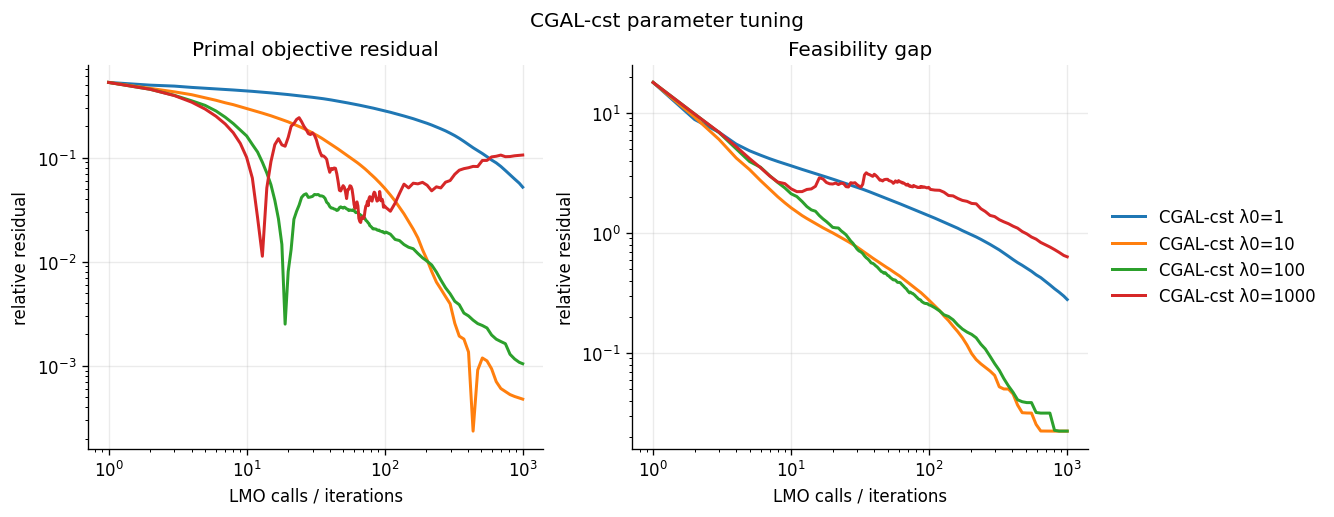

exported 4 CSV files to results/ot/


In [9]:
cgal_cst_tuning: dict[str, dict] = {}
if RUN_TUNING_EXPERIMENT:

    for lambda0 in CGAL_LAMBDAS:
        hist = cgal_ot(problem, lambda0=lambda0, bound="cst", maxiter=TUNING_MAXITER)
        cgal_cst_tuning[hist["name"]] = hist
        print(f"finished {hist['name']}: objective={hist['primal_obj'][-1]:.6e}, feas={hist['feasibility_gap'][-1]:.3e}")
    tuning_histories.update(cgal_cst_tuning)

    fig, axes = plot_ot_histories(cgal_cst_tuning, f_star, title="CGAL-cst parameter tuning")
    plt.show()
    export_histories_csv(cgal_cst_tuning, f_star, "tuning_cgal_cst")

## CGAL-dcr tuning

CGAL-dcr λ0=1: iter=10 objective=3.468082e-01 feasibility=5.054e+00


CGAL-dcr λ0=1: iter=20 objective=3.569692e-01 feasibility=4.387e+00


CGAL-dcr λ0=1: iter=40 objective=3.703061e-01 feasibility=3.806e+00


CGAL-dcr λ0=1: iter=80 objective=3.856609e-01 feasibility=3.312e+00


CGAL-dcr λ0=1: iter=160 objective=4.027949e-01 feasibility=2.888e+00


...

CGAL-dcr λ0=1000: iter=80 objective=8.885773e-01 feasibility=1.025e+00


CGAL-dcr λ0=1000: iter=160 objective=8.820342e-01 feasibility=5.577e-01


CGAL-dcr λ0=1000: iter=320 objective=8.725142e-01 feasibility=2.737e-01


CGAL-dcr λ0=1000: iter=640 objective=8.575577e-01 feasibility=1.631e-01


CGAL-dcr λ0=1000: iter=1,000 objective=8.482532e-01 feasibility=1.221e-01
finished CGAL-dcr λ0=1000: objective=8.482532e-01, feas=1.221e-01


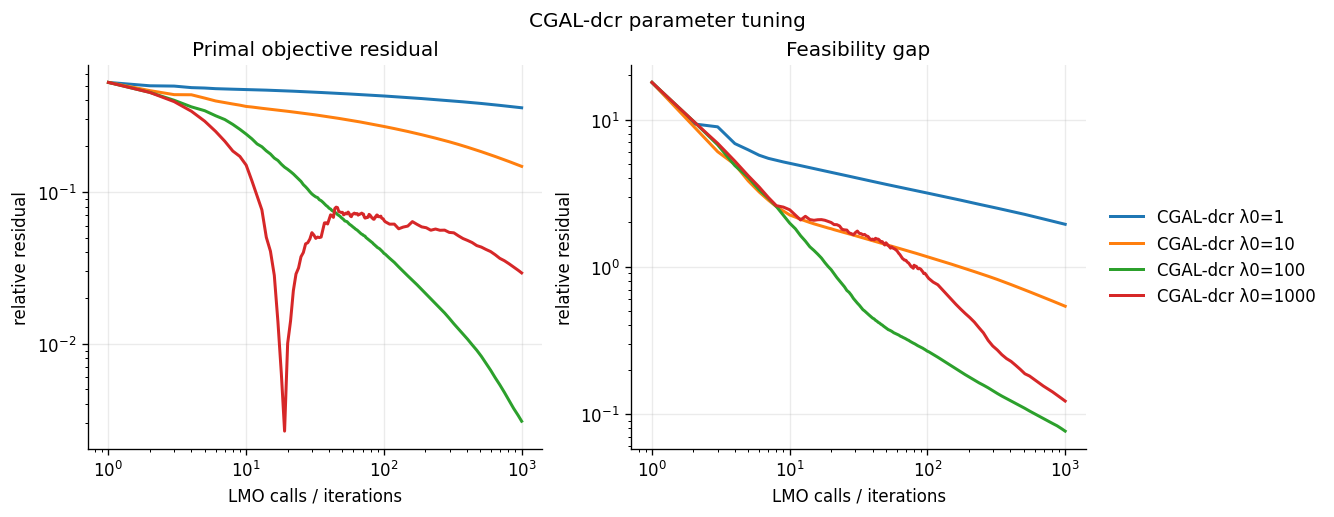

exported 4 CSV files to results/ot/


In [10]:
cgal_dcr_tuning: dict[str, dict] = {}
if RUN_TUNING_EXPERIMENT:

    for lambda0 in CGAL_LAMBDAS:
        hist = cgal_ot(problem, lambda0=lambda0, bound="dcr", maxiter=TUNING_MAXITER)
        cgal_dcr_tuning[hist["name"]] = hist
        print(f"finished {hist['name']}: objective={hist['primal_obj'][-1]:.6e}, feas={hist['feasibility_gap'][-1]:.3e}")
    tuning_histories.update(cgal_dcr_tuning)

    fig, axes = plot_ot_histories(cgal_dcr_tuning, f_star, title="CGAL-dcr parameter tuning")
    plt.show()
    export_histories_csv(cgal_dcr_tuning, f_star, "tuning_cgal_dcr")


## AdaPD tuning

AdaPD α=1: iter=10 objective=3.779176e-01 feasibility=4.023e+00


AdaPD α=1: iter=20 objective=4.084222e-01 feasibility=2.954e+00


AdaPD α=1: iter=40 objective=4.472107e-01 feasibility=2.192e+00


AdaPD α=1: iter=80 objective=4.932913e-01 feasibility=1.621e+00


AdaPD α=1: iter=160 objective=5.464332e-01 feasibility=1.177e+00


...

AdaPD α=1000: iter=80 objective=8.464807e-01 feasibility=1.345e+00


AdaPD α=1000: iter=160 objective=8.576610e-01 feasibility=9.742e-01


AdaPD α=1000: iter=320 objective=8.669537e-01 feasibility=6.401e-01


AdaPD α=1000: iter=640 objective=8.721481e-01 feasibility=3.748e-01


AdaPD α=1000: iter=1,000 objective=8.710193e-01 feasibility=2.530e-01
finished AdaPD α=1000: objective=8.710193e-01, feas=2.530e-01


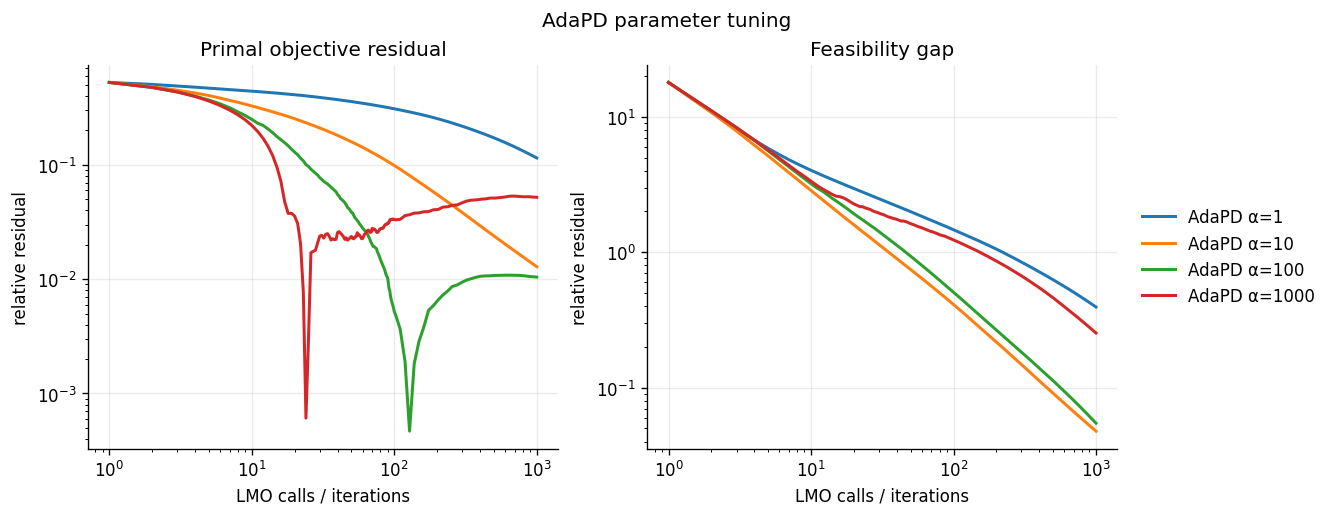

exported 4 CSV files to results/ot/


In [11]:
adapd_tuning: dict[str, dict] = {}
if RUN_TUNING_EXPERIMENT:

    for alpha in ADAPD_ALPHAS:
        hist = adapd_ot(problem, alpha=alpha, maxiter=TUNING_MAXITER)
        adapd_tuning[hist["name"]] = hist
        print(f"finished {hist['name']}: objective={hist['primal_obj'][-1]:.6e}, feas={hist['feasibility_gap'][-1]:.3e}")
    tuning_histories.update(adapd_tuning)

    fig, axes = plot_ot_histories(adapd_tuning, f_star, title="AdaPD parameter tuning")
    plt.show()
    export_histories_csv(adapd_tuning, f_star, "tuning_adapd")

## AccPD tuning

AccPD α=1: iter=10 objective=4.168473e-01 feasibility=2.791e+00


AccPD α=1: iter=20 objective=4.782986e-01 feasibility=1.848e+00


AccPD α=1: iter=40 objective=5.554266e-01 feasibility=1.197e+00


AccPD α=1: iter=80 objective=6.382486e-01 feasibility=7.562e-01


AccPD α=1: iter=160 objective=7.136710e-01 feasibility=4.499e-01


...

AccPD α=1000: iter=80 objective=8.746207e-01 feasibility=1.976e+00


AccPD α=1000: iter=160 objective=8.816015e-01 feasibility=1.332e+00


AccPD α=1000: iter=320 objective=8.824630e-01 feasibility=8.232e-01


AccPD α=1000: iter=640 objective=8.636214e-01 feasibility=4.876e-01


AccPD α=1000: iter=1,000 objective=8.512802e-01 feasibility=3.642e-01
finished AccPD α=1000: objective=8.512802e-01, feas=3.642e-01


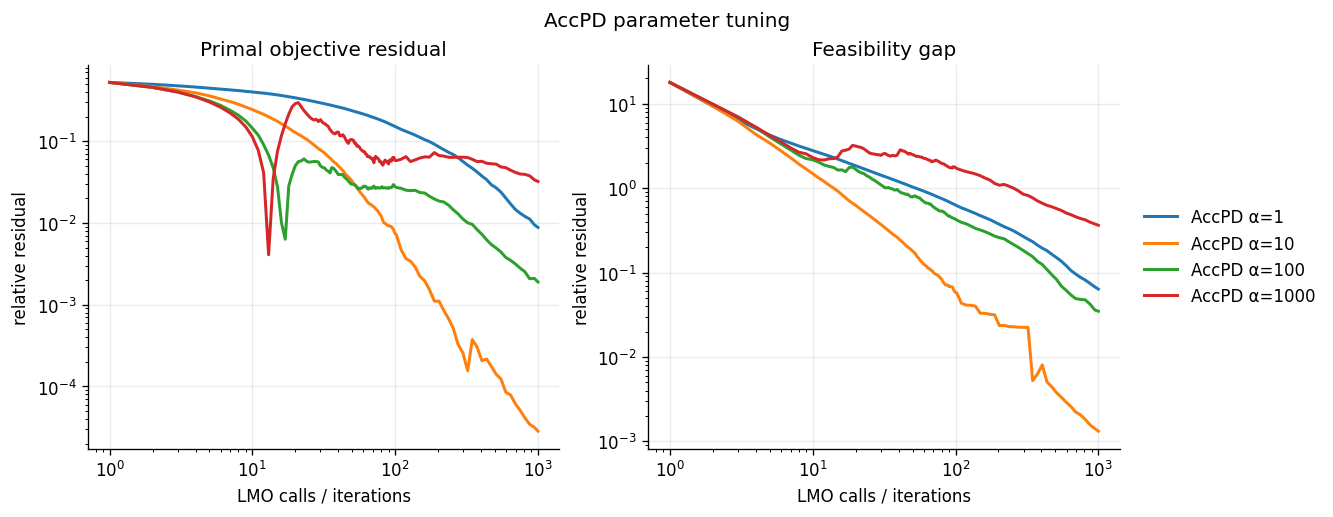

exported 4 CSV files to results/ot/


In [12]:
accpd_tuning: dict[str, dict] = {}
if RUN_TUNING_EXPERIMENT:

    for alpha in ACCPD_ALPHAS:
        hist = accpd_ot(problem, alpha=alpha, maxiter=TUNING_MAXITER)
        accpd_tuning[hist["name"]] = hist
        print(f"finished {hist['name']}: objective={hist['primal_obj'][-1]:.6e}, feas={hist['feasibility_gap'][-1]:.3e}")
    tuning_histories.update(accpd_tuning)

    fig, axes = plot_ot_histories(accpd_tuning, f_star, title="AccPD parameter tuning")
    plt.show()
    export_histories_csv(accpd_tuning, f_star, "tuning_accpd")

## Optional long runs

HCGM λ0=1000: iter=10 objective=5.788484e-01 feasibility=3.608e+00


HCGM λ0=1000: iter=20 objective=6.656581e-01 feasibility=2.049e+00


HCGM λ0=1000: iter=40 objective=7.546330e-01 feasibility=1.273e+00


HCGM λ0=1000: iter=80 objective=7.981304e-01 feasibility=8.663e-01


HCGM λ0=1000: iter=160 objective=8.237018e-01 feasibility=4.841e-01


...

AccPD α=10: iter=640 objective=8.189210e-01 feasibility=2.606e-03


AccPD α=10: iter=1,280 objective=8.189854e-01 feasibility=9.444e-04


AccPD α=10: iter=2,560 objective=8.190006e-01 feasibility=4.041e-04


AccPD α=10: iter=5,120 objective=8.189998e-01 feasibility=1.956e-04


AccPD α=10: iter=10,000 objective=8.189966e-01 feasibility=9.611e-05
finished AccPD α=10 (10,000)
exported 5 CSV files to results/ot/


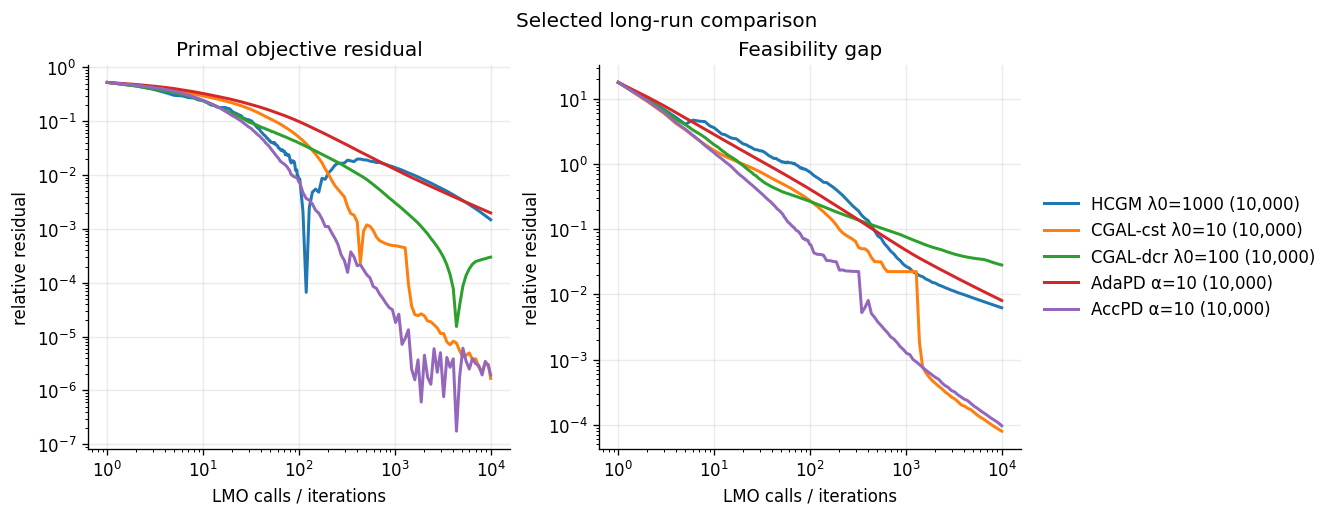

In [13]:
long_histories: dict[str, dict] = {}

if RUN_LONG_EXPERIMENT:
    for method, parameter in SELECTED_RUNS:
        if method == "HCGM":
            hist = hcgm_ot(problem, parameter, LONG_MAXITER)
        elif method == "CGAL-cst":
            hist = cgal_ot(problem, parameter, "cst", LONG_MAXITER)
        elif method == "CGAL-dcr":
            hist = cgal_ot(problem, parameter, "dcr", LONG_MAXITER)
        elif method == "AdaPD":
            hist = adapd_ot(problem, parameter, LONG_MAXITER)
        elif method == "AccPD":
            hist = accpd_ot(problem, parameter, LONG_MAXITER)
        else:
            raise ValueError(f"Unknown method: {method}")
        long_histories[f"{hist['name']} ({LONG_MAXITER:,})"] = hist
        print(f"finished {hist['name']} ({LONG_MAXITER:,})")
else:
    print("Long runs are disabled. Set RUN_LONG_EXPERIMENT = True after tuning.")


if long_histories:
    export_histories_csv(long_histories, f_star, "long")
    fig, axes = plot_ot_histories(long_histories, f_star, title="Selected long-run comparison")
    plt.show()
else:
    print("No long-run histories yet; enable RUN_LONG_EXPERIMENT and rerun the previous cell.")

## Final values

In [14]:
results_to_summarize = long_histories if long_histories else tuning_histories
summary = []
for name, hist in results_to_summarize.items():
    summary.append((hist["feasibility_gap"][-1], name))

for feas, name in sorted(summary):
    hist = results_to_summarize[name]
    print(f"{name:28s}  objective={hist['primal_obj'][-1]:.6e}  feas={feas:.3e}")

CGAL-cst λ0=10 (10,000)       objective=8.189963e-01  feas=7.957e-05
AccPD α=10 (10,000)           objective=8.189966e-01  feas=9.611e-05
HCGM λ0=1000 (10,000)         objective=8.204751e-01  feas=6.234e-03
AdaPD α=10 (10,000)           objective=8.170115e-01  feas=8.062e-03
CGAL-dcr λ0=100 (10,000)      objective=8.192937e-01  feas=2.826e-02
